# Naive session curation

In [1]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

In [2]:
def plot_selectivity_recovery(s1, left_info, right_info):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    # axarr[1,1].set_ylim(bottom=-2)

    plt.show()

In [4]:
naive_paths = [
                # r'J:\ephys_data\CW48\python\2024_10_29',
                r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                # r'J:\ephys_data\CW48\python\2024_11_01',
                # r'J:\ephys_data\CW48\python\2024_11_02',
                # r'J:\ephys_data\CW48\python\2024_11_03',
                # r'J:\ephys_data\CW48\python\2024_11_04',
                # r'J:\ephys_data\CW48\python\2024_11_05',
                # r'J:\ephys_data\CW48\python\2024_11_06',

                # r'H:\ephys_data\CW47\python\2024_10_17',

                # r'H:\ephys_data\CW47\python\2024_10_20',

                # r'H:\ephys_data\CW47\python\2024_10_21',


                # r'H:\ephys_data\CW47\python\2024_10_22',
                # r'H:\ephys_data\CW47\python\2024_10_24',
                # r'H:\ephys_data\CW47\python\2024_10_25',

                
                ]

## Behavior perf

In [64]:
path = r'N:\data\CW100\python\2026_05_18'
# path = r'M:\data\CW99\python\2026_05_11'
path = r'G:\ephys_data\CW62\python\2025_06_24'
path = r'P:\data\CW104\python\2026_10_03'

s1 = Session(path, filter_low_perf=False, filter_by_stim=False)
# earlylick, correctarr, numtrials = s1.get_acc_conv(window=12)
_, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)
# print(np.mean(correctarr))
print(proportion_correct)


27 trials removed for stability reasons
only ppyr neurons: 225 --> 196
0.18042813455657492


In [65]:
s1 = Mode(path, side='L', filter_low_perf=False, filter_by_stim=False)
print(s1.path)
cd_choice, _ = s1.plot_CD(mode_input='choice')

s1 = Mode(path, side='R',filter_low_perf=False, filter_by_stim=False)
cd_choice, _ = s1.plot_CD(mode_input='choice')

7 trials removed for stability reasons
only ppyr neurons: 87 --> 77
in house train test sorting
time taken: 3.086535692214966
P:\data\CW104\python\2026_10_03


ValueError: operands could not be broadcast together with shapes (77,7370) (77,0) 

c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: x and y must have same first dimension, but have shapes (7370,) and (1,)

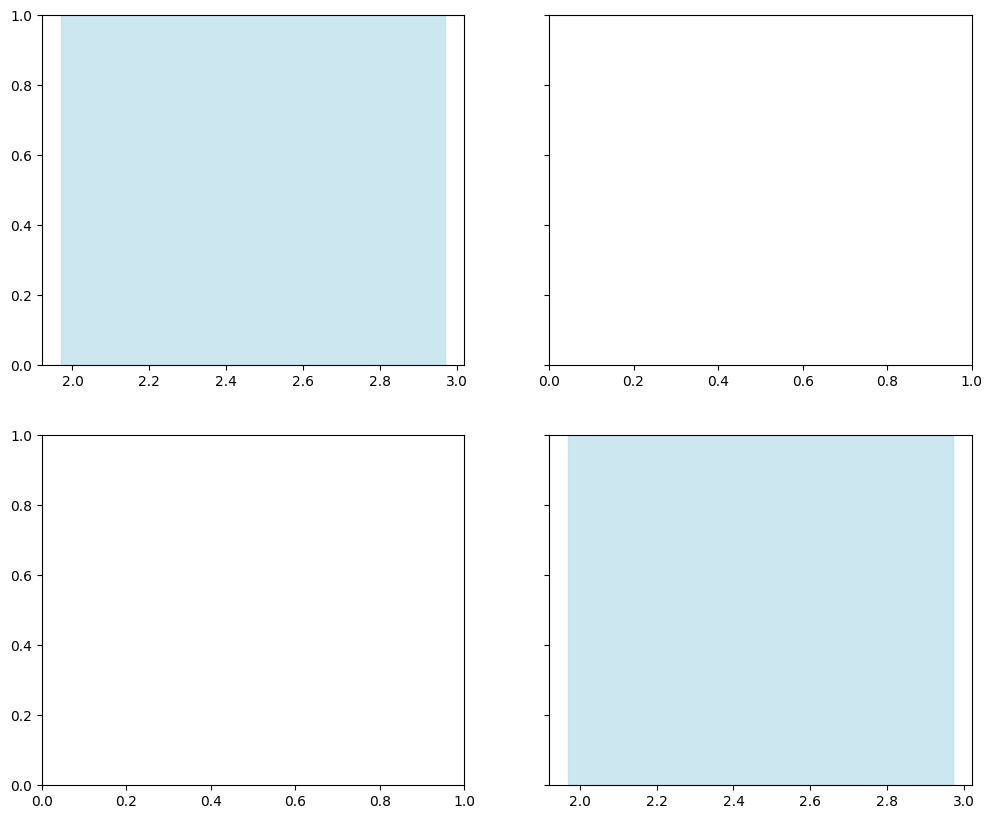

In [12]:
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.05, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)


## All prev paths

In [27]:
for path in naive_paths:
    s1 = Session(path, filter_low_perf=False, filter_by_stim=False)
    # earlylick, correctarr, numtrials = s1.get_acc_conv(window=12)
    _, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)
    # print(np.mean(correctarr))
    print(proportion_correct)


IndexError: index 0 is out of bounds for axis 1 with size 0

## CD Choice:

1 trials removed for stability reasons
only ppyr neurons: 214 --> 194
in house train test sorting
time taken: 34.19969892501831
J:\ephys_data\CW48\python\2024_10_30
calculation time: 0.15099287033081055


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


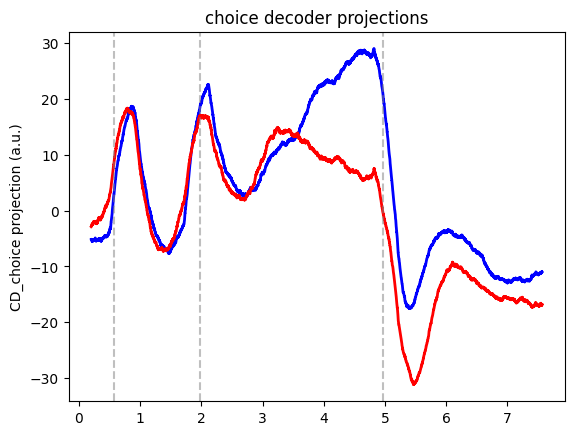

12 trials removed for stability reasons
only ppyr neurons: 171 --> 156
in house train test sorting
time taken: 31.98990273475647
calculation time: 0.11800312995910645


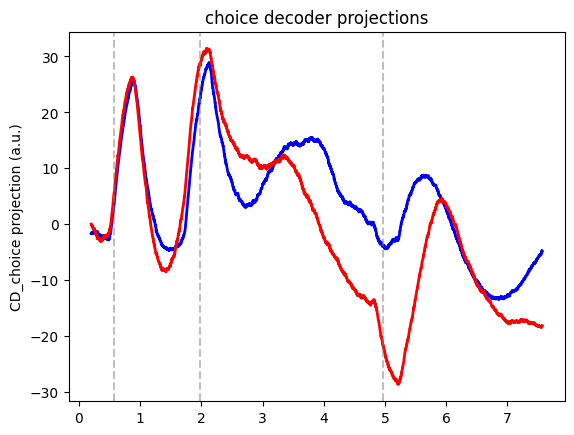

12 trials removed for stability reasons
only ppyr neurons: 173 --> 146
in house train test sorting
time taken: 24.837146759033203
J:\ephys_data\CW48\python\2024_10_31
calculation time: 0.11400008201599121


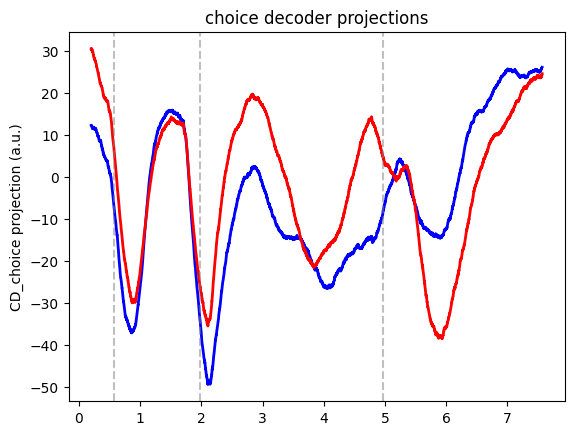

12 trials removed for stability reasons
only ppyr neurons: 126 --> 103
in house train test sorting
time taken: 15.544013023376465
calculation time: 0.0910027027130127


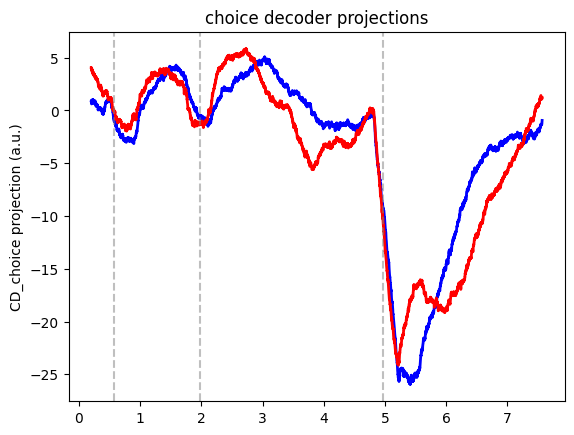

In [29]:
for path in naive_paths:
    s1 = Mode(path, side='L', filter_low_perf=False, filter_by_stim=False)
    print(s1.path)
    cd_choice, _ = s1.plot_CD(mode_input='choice')

    s1 = Mode(path, side='R',filter_low_perf=False, filter_by_stim=False)
    cd_choice, _ = s1.plot_CD(mode_input='choice')

### Decoding acc

In [36]:

path = r'J:\ephys_data\CW48\python\2024_10_30'
s1 = Mode(path, side='L', filter_low_perf=False, filter_by_stim=False)
_,_,_,db = s1.decision_boundary()
print(np.mean(db))

s1 = Mode(path, side='R', filter_low_perf=False, filter_by_stim=False)
_,_,_,db = s1.decision_boundary()
print(np.mean(db))





1 trials removed for stability reasons
only ppyr neurons: 214 --> 194
in house train test sorting
time taken: 37.7608323097229
time to calculate decoding acc: 77.91429233551025s
0.580024154589372
12 trials removed for stability reasons
only ppyr neurons: 171 --> 156
in house train test sorting
time taken: 30.415215969085693
time to calculate decoding acc: 62.97189164161682s
0.5292560975609756


In [32]:
_,_,_,db = s1.decision_boundary()


time to calculate decoding acc: 48.93478441238403s


In [34]:
np.mean(db)

0.5436612021857924

In [ ]:
naive_paths = [
                r'J:\ephys_data\CW48\python\2024_10_29',
                r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                r'J:\ephys_data\CW48\python\2024_11_05',
                r'J:\ephys_data\CW48\python\2024_11_06',

                r'H:\ephys_data\CW47\python\2024_10_17',

                r'H:\ephys_data\CW47\python\2024_10_20',

                r'H:\ephys_data\CW47\python\2024_10_21',


                r'H:\ephys_data\CW47\python\2024_10_22',
                r'H:\ephys_data\CW47\python\2024_10_24',
                r'H:\ephys_data\CW47\python\2024_10_25',

                
                ]

all_dbs_L = []
all_dbs_R = []
for path in naive_paths:
    s1 = Mode(path, side='L', filter_low_perf=False, filter_by_stim=False)
    _,_,_,db = s1.decision_boundary()
    all_dbs_L.append(np.mean(db))
    s1 = Mode(path, side='R', filter_low_perf=False, filter_by_stim=False)
    _,_,_,db = s1.decision_boundary()
    all_dbs_R.append(np.mean(db))




13 trials removed for stability reasons
only ppyr neurons: 214 --> 190
in house train test sorting
time taken: 37.347087383270264
time to calculate decoding acc: 75.21181225776672s
17 trials removed for stability reasons
only ppyr neurons: 119 --> 109
in house train test sorting
time taken: 18.082237005233765
time to calculate decoding acc: 40.54002285003662s
1 trials removed for stability reasons
only ppyr neurons: 214 --> 194
in house train test sorting
time taken: 35.23838448524475
time to calculate decoding acc: 74.20473265647888s
12 trials removed for stability reasons
only ppyr neurons: 171 --> 156
in house train test sorting
time taken: 28.23479914665222
time to calculate decoding acc: 58.64400362968445s
12 trials removed for stability reasons
only ppyr neurons: 173 --> 146
in house train test sorting
time taken: 22.65188765525818
time to calculate decoding acc: 48.0895094871521s
12 trials removed for stability reasons
only ppyr neurons: 126 --> 103
in house train test sorting
t

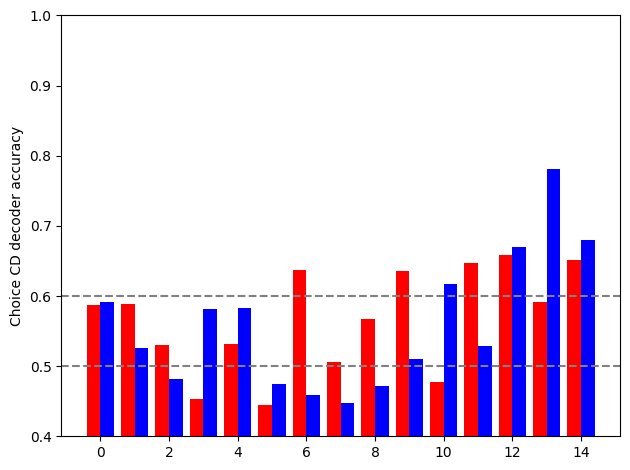

In [50]:
plt.bar(np.arange(len(all_dbs_L)) -0.2, all_dbs_L, color='red', width=0.4)
plt.bar(np.arange(len(all_dbs_R)) +0.2, all_dbs_R, color='blue', width=0.4)
plt.axhline(0.5, color='grey', ls='--')
plt.axhline(0.6, color='grey', ls='--')
plt.ylim(0.4,1)
plt.ylabel('Choice CD decoder accuracy')
# plt.xticks(np.arange(len(all_dbs_L)), naive_paths, rotation=45)
plt.tight_layout()
plt.show()